# Integrated Infrastructure Analysis — Hyderabad

**Goal:** Combine infrastructure-point and road datasets using a common 1 km geographic grid.

This is a spatial coverage and density analysis. It does **not** produce validated risk labels, travel times, road-network connectivity, or emergency response times.

**Why a grid?** Infrastructure records and road records describe different entities and have very different row counts. A row-by-row join would create misleading matches. Instead, both datasets are assigned to the same geographic cells and aggregated independently before being compared.

**Important limitations**
- Road locations are representative points, not full road geometries.
- A road segment may cross a grid cell even if its representative point lies in another cell.
- OSM facility/road coverage may be incomplete.
- A low count is a signal for further investigation, not proof of inadequate service.


In [1]:
from pathlib import Path
import os
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

warnings.filterwarnings("ignore")

PROJECT_DIR = Path(r"C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics")
if not PROJECT_DIR.exists():
    raise FileNotFoundError(f"Project folder not found: {PROJECT_DIR}")

os.chdir(PROJECT_DIR)

INFRA_DIR = PROJECT_DIR / "data/processed/infrastructure"
INFRA_EXPERIMENT_DIR = INFRA_DIR / "infrastructure_points_experiments"
ROADS_EXPERIMENT_DIR = INFRA_DIR / "roads_experiments"
OUTPUT_DIR = INFRA_DIR / "integrated_infrastructure_experiments"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

GRID_SIZE_KM = 1.0
RANDOM_STATE = 42

print("Project directory:", PROJECT_DIR)
print("Infrastructure folder exists:", INFRA_DIR.exists())
print("Roads folder exists:", ROADS_EXPERIMENT_DIR.exists())
print("Output folder:", OUTPUT_DIR)


Project directory: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics
Infrastructure folder exists: True
Roads folder exists: True
Output folder: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\infrastructure\integrated_infrastructure_experiments


## 1. Load the two datasets

The infrastructure-points notebook produced a file containing `category`, `latitude`, and `longitude`. The roads notebook may have produced an enriched output or we can safely fall back to `roads_processed.csv`.

The loader below searches the expected folders and selects a CSV by its required columns. It does not join rows from the two datasets.


In [2]:
def find_csv_with_columns(search_dirs, required_columns, preferred_names=None):
    preferred_names = preferred_names or []
    candidates = []

    for folder in search_dirs:
        if folder.exists():
            candidates.extend(folder.glob("*.csv"))

    # Try preferred filenames first, then the remaining CSV files.
    ordered = []
    for name in preferred_names:
        ordered.extend([p for p in candidates if p.name.lower() == name.lower()])
    ordered.extend([p for p in candidates if p not in ordered])

    checked = []
    for path in ordered:
        try:
            header = pd.read_csv(path, nrows=0)
            columns = set(header.columns.str.lower())
            checked.append((str(path), sorted(columns)))
            if set(c.lower() for c in required_columns).issubset(columns):
                return path
        except Exception:
            continue

    raise FileNotFoundError(
        f"No CSV found with columns {required_columns}. "
        f"Checked: {checked[:20]}"
    )


infra_path = find_csv_with_columns(
    [INFRA_EXPERIMENT_DIR, INFRA_DIR],
    ["category", "latitude", "longitude"],
    preferred_names=["infrastructure_points_with_clusters_and_density.csv"]
)

roads_path = find_csv_with_columns(
    [ROADS_EXPERIMENT_DIR, INFRA_DIR],
    ["road_type", "latitude", "longitude", "length_km"],
    preferred_names=["roads_with_density_and_clusters.csv", "roads_processed.csv"]
)

infra = pd.read_csv(infra_path)
roads = pd.read_csv(roads_path)

print("Infrastructure file:", infra_path)
print("Infrastructure shape:", infra.shape)
print("Roads file:", roads_path)
print("Roads shape:", roads.shape)

display(infra.head())
display(roads.head())


Infrastructure file: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\infrastructure\infrastructure_points_experiments\infrastructure_points_with_clusters_and_density.csv
Infrastructure shape: (2083, 17)
Roads file: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\infrastructure\roads_processed.csv
Roads shape: (93437, 8)


,osm_id,category,name,subtype,latitude,longitude,asset_name,x_km,y_km,kmeans_cluster,dbscan_cluster,nearby_asset_count_1km,nearby_hospital_count_1km,nearby_fire_station_count_1km,nearby_building_count_1km,nearest_hospital_distance_km,nearest_fire_station_distance_km
0,relation/5321005,hospital,Shadan Hospital,hospital,17.352109,78.373614,Shadan Hospital,-7.960827,-9.461684,0,-1,1,1,0,0,0.0,7.707748
1,relation/5330163,hospital,Nizams Institute of Medical Sciences Hospital ...,hospital,17.422625,78.453436,Nizams Institute of Medical Sciences Hospital ...,0.516609,-1.664493,1,0,51,35,0,16,0.0,3.415203
2,relation/11902466,hospital,AIG HOSPITALS,hospital,17.443208,78.366195,AIG HOSPITALS,-8.748702,0.611541,0,-1,24,7,0,17,0.0,5.658294
3,way/31549640,hospital,Axon Hospital,hospital,17.439328,78.442376,Axon Hospital,-0.657977,0.182502,1,1,72,26,0,46,0.0,2.848032
4,way/116037991,hospital,Virinchi Hospitals,hospital,17.408080,78.451495,Virinchi Hospitals,0.310435,-3.272780,1,-1,22,16,0,6,0.0,4.550061


,osm_id,road_name,road_type,maxspeed,oneway,latitude,longitude,length_km
0,way/22831055,NaN,trunk,60.0,yes,17.401277,78.549785,1.7416
1,way/22839614,Brigadier Sayeed Road,tertiary,NaN,no,17.467287,78.482014,0.3261
2,way/22839658,NaN,trunk,50.0,NaN,17.384764,78.498192,0.7703
3,way/22839666,NaN,secondary,NaN,NaN,17.458340,78.513146,0.5193
4,way/22839714,Sainikpuri Road,secondary,60.0,yes,17.480535,78.534132,0.5061


## 2. Audit and standardize coordinates

We retain valid coordinate records and standardize category/type text. Missing speed limits, road names, and one-way values are not converted to zero or guessed.

The original input files remain unchanged.


In [3]:
def clean_coordinates(df, label):
    out = df.copy()
    out.columns = out.columns.str.strip().str.lower()

    for col in ["latitude", "longitude"]:
        out[col] = pd.to_numeric(out[col], errors="coerce")

    valid = (
        out["latitude"].between(-90, 90)
        & out["longitude"].between(-180, 180)
        & out["latitude"].notna()
        & out["longitude"].notna()
    )

    removed = int((~valid).sum())
    out = out.loc[valid].copy()
    print(f"{label}: {len(out):,} valid rows; {removed:,} invalid-coordinate rows removed")
    return out


infra = clean_coordinates(infra, "Infrastructure")
roads = clean_coordinates(roads, "Roads")

infra["category"] = infra["category"].astype("string").str.strip().str.lower()
roads["road_type"] = roads["road_type"].astype("string").str.strip().str.lower()
roads["length_km"] = pd.to_numeric(roads["length_km"], errors="coerce")

print("\nInfrastructure categories:")
display(infra["category"].value_counts(dropna=False).rename("records").to_frame())

print("\nRoad types:")
display(roads["road_type"].value_counts(dropna=False).rename("records").to_frame())

print("\nCoordinate ranges:")
print("Infrastructure latitude:", infra.latitude.min(), "to", infra.latitude.max())
print("Infrastructure longitude:", infra.longitude.min(), "to", infra.longitude.max())
print("Road latitude:", roads.latitude.min(), "to", roads.latitude.max())
print("Road longitude:", roads.longitude.min(), "to", roads.longitude.max())


Infrastructure: 2,083 valid rows; 0 invalid-coordinate rows removed
Roads: 93,437 valid rows; 0 invalid-coordinate rows removed

Infrastructure categories:


,records
category,
hospital,1073
building,1003
fire_station,7



Road types:


,records
road_type,
residential,85620
tertiary,3138
secondary,1780
primary,1468
trunk,836
unclassified,464
motorway,131



Coordinate ranges:
Infrastructure latitude: 17.2599543 to 17.5458731
Infrastructure longitude: 78.2524483 to 78.632292
Road latitude: 17.277726598101264 to 17.557367581818184
Road longitude: 78.23883746666667 to 78.625484792


## 3. Create a common 1 km grid

For Hyderabad's compact study area, we use a local equirectangular approximation to convert latitude/longitude differences into kilometres. The same origin and conversion are used for both datasets, so records can be assigned to identical 1 km cells.

This is suitable for exploratory city-scale aggregation, not precision surveying. A projected CRS such as UTM Zone 44N should be used for a production GIS workflow.


In [4]:
all_lat = pd.concat([infra["latitude"], roads["latitude"]], ignore_index=True)
all_lon = pd.concat([infra["longitude"], roads["longitude"]], ignore_index=True)

LAT0 = float(all_lat.min())
LON0 = float(all_lon.min())
LAT0_RAD = np.deg2rad(LAT0)

KM_PER_DEG_LAT = 110.574
KM_PER_DEG_LON = 111.320 * np.cos(LAT0_RAD)

def add_grid_columns(df):
    out = df.copy()
    out["x_km"] = (out["longitude"] - LON0) * KM_PER_DEG_LON
    out["y_km"] = (out["latitude"] - LAT0) * KM_PER_DEG_LAT
    out["grid_x"] = np.floor(out["x_km"] / GRID_SIZE_KM).astype("int32")
    out["grid_y"] = np.floor(out["y_km"] / GRID_SIZE_KM).astype("int32")
    out["grid_id"] = (
        out["grid_x"].astype(str) + "_" + out["grid_y"].astype(str)
    )
    return out

infra = add_grid_columns(infra)
roads = add_grid_columns(roads)

print("Grid size (km):", GRID_SIZE_KM)
print("Grid origin (latitude, longitude):", (LAT0, LON0))
print("Infrastructure occupied cells:", infra["grid_id"].nunique())
print("Road occupied cells:", roads["grid_id"].nunique())


Grid size (km): 1.0
Grid origin (latitude, longitude): (17.2599543, 78.23883746666667)
Infrastructure occupied cells: 416
Road occupied cells: 763


## 4. Aggregate infrastructure within each cell

We count each infrastructure category separately. This produces interpretable features such as hospital count and fire-station count per cell.

These are counts of records in the source dataset, not verified complete facility inventories.


In [5]:
infra_counts = (
    infra.pivot_table(
        index=["grid_id", "grid_x", "grid_y"],
        columns="category",
        values="latitude",
        aggfunc="count",
        fill_value=0
    )
    .reset_index()
)

infra_counts.columns.name = None
category_columns = [
    c for c in infra_counts.columns
    if c not in ["grid_id", "grid_x", "grid_y"]
]
infra_counts = infra_counts.rename(
    columns={c: f"infra_{str(c).replace(' ', '_')}_count" for c in category_columns}
)

print("Infrastructure grid summary shape:", infra_counts.shape)
display(infra_counts.head())


Infrastructure grid summary shape: (416, 6)


,grid_id,grid_x,grid_y,infra_building_count,infra_fire_station_count,infra_hospital_count
0,10_10,10,10,0,0,1
1,10_17,10,17,7,0,1
2,10_18,10,18,6,0,0
3,10_19,10,19,1,0,0
4,10_21,10,21,1,0,0


## 5. Aggregate road information within each cell

For each cell we calculate:
- Number of road representative points.
- Sum of the recorded `length_km` values associated with those points.
- Mean recorded segment length.
- Counts by road type.

**Caution:** The sum is the sum of source segment lengths assigned by representative point. It is not an exact measurement of road length physically inside each grid cell.


In [6]:
roads_valid_length = roads.loc[
    roads["length_km"].notna() & (roads["length_km"] > 0)
].copy()

road_summary = (
    roads.groupby(["grid_id", "grid_x", "grid_y"], as_index=False)
    .agg(
        road_representative_point_count=("road_type", "size"),
        road_segment_length_sum_km=("length_km", "sum"),
        mean_recorded_segment_length_km=("length_km", "mean"),
        unique_road_types=("road_type", "nunique")
    )
)

road_type_counts = (
    roads.pivot_table(
        index=["grid_id", "grid_x", "grid_y"],
        columns="road_type",
        values="latitude",
        aggfunc="count",
        fill_value=0
    )
    .reset_index()
)
road_type_counts.columns.name = None
road_type_columns = [
    c for c in road_type_counts.columns
    if c not in ["grid_id", "grid_x", "grid_y"]
]
road_type_counts = road_type_counts.rename(
    columns={c: f"roadtype_{str(c).replace(' ', '_')}_count" for c in road_type_columns}
)

print("Road grid summary shape:", road_summary.shape)
display(road_summary.head())


Road grid summary shape: (763, 7)


,grid_id,grid_x,grid_y,road_representative_point_count,road_segment_length_sum_km,mean_recorded_segment_length_km,unique_road_types
0,0_29,0,29,2,1.8762,0.938100,2
1,0_30,0,30,26,4.3406,0.166946,5
2,0_31,0,31,5,2.6975,0.539500,1
3,10_16,10,16,4,0.2473,0.061825,1
4,10_17,10,17,53,9.0150,0.170094,3


## 6. Integrate both summaries on the common grid

This is the key integration step. We take the union of cells occupied by either dataset and fill absent counts with zero.

A zero means no matching source records were assigned to that cell; it does not prove that no facility or road exists there.


In [7]:
integrated = infra_counts.merge(
    road_summary,
    on=["grid_id", "grid_x", "grid_y"],
    how="outer"
)

integrated = integrated.merge(
    road_type_counts,
    on=["grid_id", "grid_x", "grid_y"],
    how="left"
)

numeric_columns = integrated.select_dtypes(include="number").columns
integrated[numeric_columns] = integrated[numeric_columns].fillna(0)

integrated["cell_center_x_km"] = (
    integrated["grid_x"] + 0.5
) * GRID_SIZE_KM
integrated["cell_center_y_km"] = (
    integrated["grid_y"] + 0.5
) * GRID_SIZE_KM

integrated["cell_center_longitude"] = (
    LON0 + integrated["cell_center_x_km"] / KM_PER_DEG_LON
)
integrated["cell_center_latitude"] = (
    LAT0 + integrated["cell_center_y_km"] / KM_PER_DEG_LAT
)

infra_count_cols = [c for c in integrated.columns if c.startswith("infra_") and c.endswith("_count")]
roadtype_count_cols = [c for c in integrated.columns if c.startswith("roadtype_") and c.endswith("_count")]

integrated["total_infrastructure_records"] = (
    integrated[infra_count_cols].sum(axis=1) if infra_count_cols else 0
)
integrated["total_road_type_records"] = (
    integrated[roadtype_count_cols].sum(axis=1) if roadtype_count_cols else 0
)

print("Integrated grid shape:", integrated.shape)
print("Grid cells:", len(integrated))
display(integrated.head(10))


Integrated grid shape: (791, 23)
Grid cells: 791


,grid_id,grid_x,grid_y,infra_building_count,infra_fire_station_count,infra_hospital_count,road_representative_point_count,road_segment_length_sum_km,mean_recorded_segment_length_km,unique_road_types,...,roadtype_secondary_count,roadtype_tertiary_count,roadtype_trunk_count,roadtype_unclassified_count,cell_center_x_km,cell_center_y_km,cell_center_longitude,cell_center_latitude,total_infrastructure_records,total_road_type_records
0,0_29,0,29,0.0,0.0,0.0,2,1.8762,0.938100,2.0,...,1.0,0.0,0.0,0.0,0.5,29.5,78.243541,17.526744,0.0,2.0
1,0_30,0,30,0.0,0.0,0.0,26,4.3406,0.166946,5.0,...,2.0,1.0,8.0,0.0,0.5,30.5,78.243541,17.535788,0.0,26.0
2,0_31,0,31,0.0,0.0,0.0,5,2.6975,0.539500,1.0,...,0.0,0.0,0.0,0.0,0.5,31.5,78.243541,17.544831,0.0,5.0
3,10_10,10,10,0.0,0.0,1.0,0,0.0000,0.000000,0.0,...,0.0,0.0,0.0,0.0,10.5,10.5,78.337608,17.354913,1.0,0.0
4,10_16,10,16,0.0,0.0,0.0,4,0.2473,0.061825,1.0,...,0.0,0.0,0.0,0.0,10.5,16.5,78.337608,17.409176,0.0,4.0
5,10_17,10,17,7.0,0.0,1.0,53,9.0150,0.170094,3.0,...,2.0,12.0,0.0,0.0,10.5,17.5,78.337608,17.418219,8.0,53.0
6,10_18,10,18,6.0,0.0,0.0,43,7.7580,0.180419,3.0,...,16.0,9.0,0.0,0.0,10.5,18.5,78.337608,17.427263,6.0,43.0
7,10_19,10,19,1.0,0.0,0.0,52,9.5818,0.184265,2.0,...,0.0,9.0,0.0,0.0,10.5,19.5,78.337608,17.436307,1.0,52.0
8,10_20,10,20,0.0,0.0,0.0,27,4.4665,0.165426,2.0,...,0.0,2.0,0.0,0.0,10.5,20.5,78.337608,17.445351,0.0,27.0
9,10_21,10,21,1.0,0.0,0.0,36,10.2890,0.285806,2.0,...,0.0,0.0,0.0,0.0,10.5,21.5,78.337608,17.454394,1.0,36.0


## 7. Exploratory analysis of integrated areas

We compare cells by infrastructure counts and road indicators. The rankings are descriptive only. They are not risk rankings because population, demand, facility capacity, road connectivity, and validated hazard exposure are not included yet.


,grid_id,total_infrastructure_records,road_representative_point_count,road_segment_length_sum_km
742,5_24,85.0,13,7.5655
597,34_15,47.0,197,29.3166
447,28_18,41.0,189,25.3750
727,4_24,38.0,26,7.3632
92,15_20,34.0,151,23.0156
120,16_25,34.0,138,25.2131
69,14_20,29.0,92,11.9999
290,22_20,29.0,219,21.3750
91,15_19,28.0,89,13.4193
147,17_25,25.0,131,20.7654


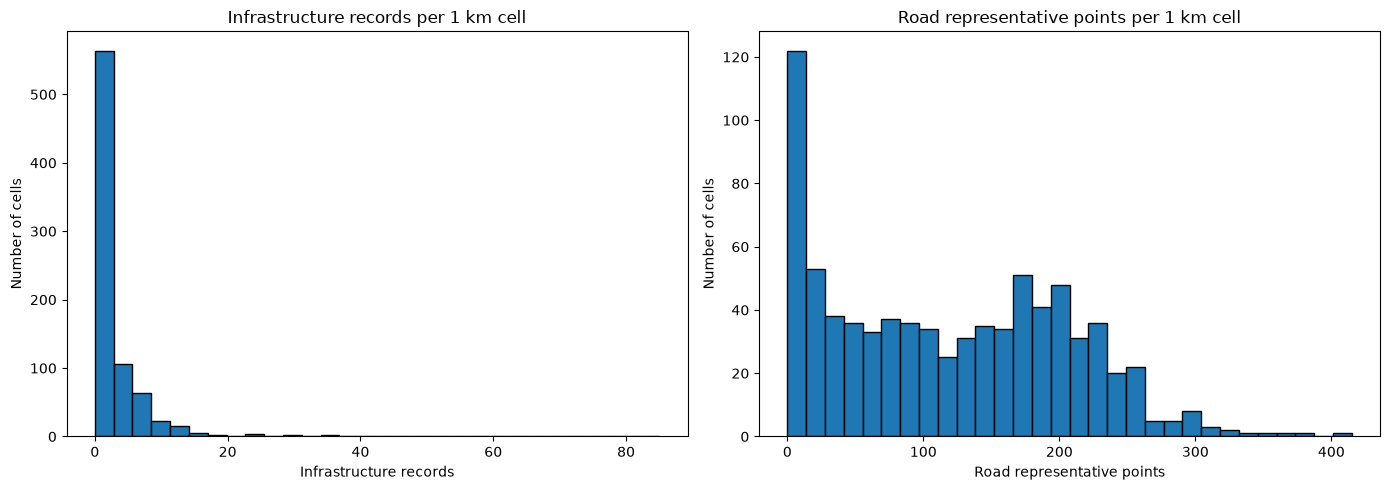

In [8]:
display(
    integrated[
        [
            "grid_id",
            "total_infrastructure_records",
            "road_representative_point_count",
            "road_segment_length_sum_km"
        ]
    ]
    .sort_values("total_infrastructure_records", ascending=False)
    .head(15)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(
    integrated["total_infrastructure_records"],
    bins=30,
    edgecolor="black"
)
axes[0].set_title("Infrastructure records per 1 km cell")
axes[0].set_xlabel("Infrastructure records")
axes[0].set_ylabel("Number of cells")

axes[1].hist(
    integrated["road_representative_point_count"],
    bins=30,
    edgecolor="black"
)
axes[1].set_title("Road representative points per 1 km cell")
axes[1].set_xlabel("Road representative points")
axes[1].set_ylabel("Number of cells")

plt.tight_layout()
plt.show()


## 8. Visualize the integrated grid

The scatter plot uses cell-centre coordinates. Marker size reflects the number of infrastructure records, while colour represents road representative-point count. This is an exploratory plot, not a precise GIS map.


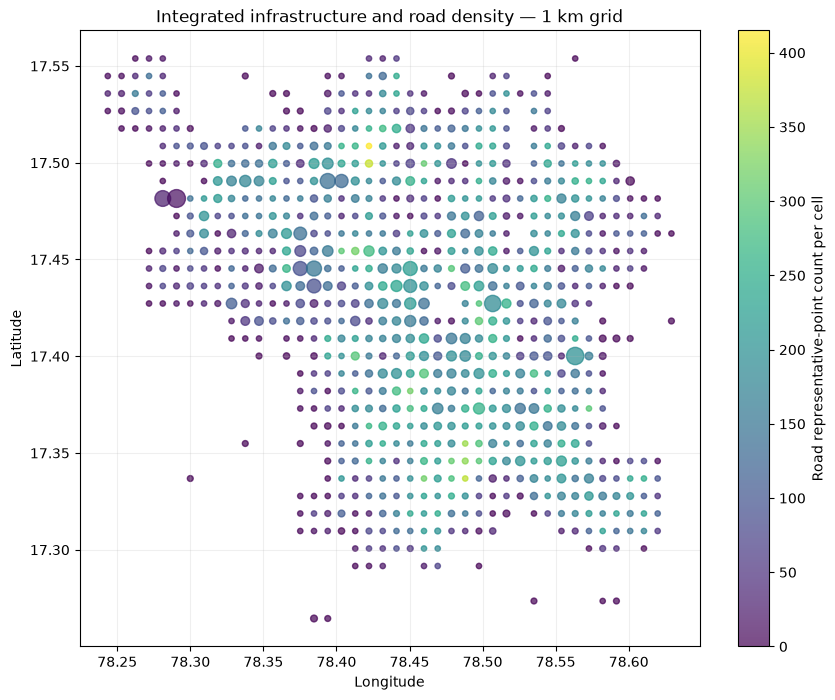

In [9]:
plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    integrated["cell_center_longitude"],
    integrated["cell_center_latitude"],
    s=15 + integrated["total_infrastructure_records"].clip(upper=50) * 3,
    c=integrated["road_representative_point_count"],
    alpha=0.7
)
plt.colorbar(scatter, label="Road representative-point count per cell")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Integrated infrastructure and road density — 1 km grid")
plt.grid(alpha=0.2)
plt.show()


## 9. Identify cells for further investigation

We create transparent descriptive flags:
- `low_infrastructure_records`: cells in the bottom quartile of infrastructure counts.
- `low_road_point_count`: cells in the bottom quartile of road representative-point counts.

These are relative flags within the observed grid. They are **not** a risk classifier and should not be presented as confirmed underserved or unsafe areas.


In [10]:
infra_q25 = integrated["total_infrastructure_records"].quantile(0.25)
roads_q25 = integrated["road_representative_point_count"].quantile(0.25)

integrated["low_infrastructure_records"] = (
    integrated["total_infrastructure_records"] <= infra_q25
)
integrated["low_road_point_count"] = (
    integrated["road_representative_point_count"] <= roads_q25
)

integrated["investigation_flag"] = (
    integrated["low_infrastructure_records"]
    & integrated["low_road_point_count"]
)

print("Infrastructure bottom-quartile threshold:", infra_q25)
print("Road-point bottom-quartile threshold:", roads_q25)
print("Cells flagged for further investigation:", int(integrated["investigation_flag"].sum()))

display(
    integrated.loc[integrated["investigation_flag"]]
    .sort_values(
        ["total_infrastructure_records", "road_representative_point_count"]
    )
    .head(20)
)


Infrastructure bottom-quartile threshold: 0.0
Road-point bottom-quartile threshold: 34.0
Cells flagged for further investigation: 133


,grid_id,grid_x,grid_y,infra_building_count,infra_fire_station_count,infra_hospital_count,road_representative_point_count,road_segment_length_sum_km,mean_recorded_segment_length_km,unique_road_types,...,roadtype_unclassified_count,cell_center_x_km,cell_center_y_km,cell_center_longitude,cell_center_latitude,total_infrastructure_records,total_road_type_records,low_infrastructure_records,low_road_point_count,investigation_flag
64,14_14,14,14,0.0,0.0,0.0,1,0.0708,0.0708,1.0,...,0.0,14.5,14.5,78.375235,17.391088,0.0,1.0,True,True,True
133,17_11,17,11,0.0,0.0,0.0,1,1.0855,1.0855,1.0,...,0.0,17.5,11.5,78.403455,17.363957,0.0,1.0,True,True,True
179,18_3,18,3,0.0,0.0,0.0,1,1.8214,1.8214,1.0,...,0.0,18.5,3.5,78.412862,17.291607,0.0,1.0,True,True,True
353,24_29,24,29,0.0,0.0,0.0,1,0.0977,0.0977,1.0,...,0.0,24.5,29.5,78.469302,17.526744,0.0,1.0,True,True,True
432,27_3,27,3,0.0,0.0,0.0,1,4.8717,4.8717,1.0,...,0.0,27.5,3.5,78.497522,17.291607,0.0,1.0,True,True,True
433,27_30,27,30,0.0,0.0,0.0,1,1.6876,1.6876,1.0,...,0.0,27.5,30.5,78.497522,17.535788,0.0,1.0,True,True,True
462,28_6,28,6,0.0,0.0,0.0,1,1.0231,1.0231,1.0,...,0.0,28.5,6.5,78.506929,17.318738,0.0,1.0,True,True,True
492,2_28,2,28,0.0,0.0,0.0,1,0.0134,0.0134,1.0,...,0.0,2.5,28.5,78.262354,17.517700,0.0,1.0,True,True,True
538,31_6,31,6,0.0,0.0,0.0,1,0.0326,0.0326,1.0,...,0.0,31.5,6.5,78.535149,17.318738,0.0,1.0,True,True,True
563,32_31,32,31,0.0,0.0,0.0,1,1.1798,1.1798,1.0,...,0.0,32.5,31.5,78.544556,17.544831,0.0,1.0,True,True,True


## 10. Save integrated outputs and metadata

We save the integrated grid as a new processed dataset. Original source files are not overwritten.


In [11]:
output_csv = OUTPUT_DIR / "integrated_infrastructure_road_grid_1km.csv"
metadata_path = OUTPUT_DIR / "integration_summary.json"

integrated.to_csv(output_csv, index=False)

summary = {
    "infrastructure_source_file": str(infra_path),
    "roads_source_file": str(roads_path),
    "infrastructure_source_records_after_coordinate_filter": int(len(infra)),
    "road_source_records_after_coordinate_filter": int(len(roads)),
    "grid_size_km": GRID_SIZE_KM,
    "grid_origin_latitude": LAT0,
    "grid_origin_longitude": LON0,
    "integrated_grid_cells": int(len(integrated)),
    "infrastructure_categories": sorted(infra["category"].dropna().astype(str).unique().tolist()),
    "road_types": sorted(roads["road_type"].dropna().astype(str).unique().tolist()),
    "cells_flagged_for_further_investigation": int(integrated["investigation_flag"].sum()),
    "supervised_model_trained": False,
    "validated_risk_labels_available": False,
    "road_geometry_available": False,
    "interpretation": (
        "Exploratory common-grid aggregation of infrastructure records and road "
        "representative points. Relative low-count flags are for investigation only; "
        "not validated risk or service-adequacy labels."
    )
}

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=4)

print("Saved integrated dataset:", output_csv)
print("Saved metadata:", metadata_path)
print(json.dumps(summary, indent=4))


Saved integrated dataset: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\infrastructure\integrated_infrastructure_experiments\integrated_infrastructure_road_grid_1km.csv
Saved metadata: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\infrastructure\integrated_infrastructure_experiments\integration_summary.json
{
    "infrastructure_source_file": "C:\\Users\\sanaf\\OneDrive\\Desktop\\urban-risk-analytics\\data\\processed\\infrastructure\\infrastructure_points_experiments\\infrastructure_points_with_clusters_and_density.csv",
    "roads_source_file": "C:\\Users\\sanaf\\OneDrive\\Desktop\\urban-risk-analytics\\data\\processed\\infrastructure\\roads_processed.csv",
    "infrastructure_source_records_after_coordinate_filter": 2083,
    "road_source_records_after_coordinate_filter": 93437,
    "grid_size_km": 1.0,
    "grid_origin_latitude": 17.2599543,
    "grid_origin_longitude": 78.23883746666667,
    "integrated_grid_cells": 791,
    "infrastructu

## 11. Methodological limitations and next steps

### What this integration gives us
- A common geographic unit for comparing infrastructure and roads.
- Counts by facility category and road type.
- Approximate road-segment length totals assigned by representative point.
- Relative low-count flags to guide further investigation.

### What it does not give us
- Exact road length inside each cell.
- Network connectivity or shortest travel routes.
- Emergency response time or accessibility.
- Complete facility coverage or capacity.
- A validated urban-risk score.

### Recommended next step
Integrate the flood and heat datasets on the same geographic reference, after checking their spatial coverage and temporal meaning. Then develop a transparent prioritization framework using defensible indicators and clearly documented limitations.
